In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/RNN

/Users/cl1704/PycharmProjects/embedding_dimension/RNN


In [2]:
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
import matplotlib
import torch
from Experiment_10.net import Net
import torch
from Experiment_10.ParametricWMTask import generate_trials
from sklearn.decomposition import PCA
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [7]:
df_list = []
for filename in os.listdir('Experiment_10/Results_10'):
    f = os.path.join('Experiment_10/Results_10', filename)
    if os.path.isfile(f):
        df_list.append(pd.read_pickle(f))
df = pd.concat(df_list,ignore_index=True)
#df = df[df.n>=75]
#df = df[(df.pca_1>.07) ]
# df = df[(df.gain_mean>.1) & (df.gain_mean<.7)]
#df = df[df.non_linearity_std<.015]
#df.pca_error = np.log10(df.pca_error)
# df.gain_mean = np.log10(df.gain_mean)

# df.linear_error_max=df.linear_error_max.apply(lambda x: x.item())
# df.linear_error_min=df.linear_error_min.apply(lambda x: x.item())
# df.linear_error_mean=df.linear_error_mean.apply(lambda x: x.item())
#df['diff']  = df.linear_error_max - df.linear_error_min

# df['diff'] = np.abs(df.linear_error_max-df.linear_error_min)
# df['linear_error'] = (df.linear_error_max+df.linear_error_min)/2
#df  = df[df.linear_error_min<1]
#df  = df[df.linear_error_std<.05]
#df  = df[df.pca_1>.2]
#df  = df[df.lambda_linear>.1]
#df  = df[df['diff']<.5]

#df  = df[df.linear_error_std<.4]

#df.pca_error = np.log10(df.pca_error)

In [8]:
df

,model_id,epochs,sigma_rec,sigma_in,weight_decay,beta,lr,lambda_std,pca_target_2,lambda_pca_1,...,n,dim,pca_error,pca_1,snr_mean,snr,gain,kmeans_error,lambda_gain_mean,lambda_gain_std
0,LFCpLZIo,1000,0.1,0.0,0.001,20,0.005,0.4,0.560606,1,...,98,4,0.525980,0.106649,0.027650,"[0.020506782, 0.029345548, 0.034314584, 0.0288...","[0.5450563, 0.55175334, 0.58276826, 0.4929288,...",0.616232,1,1
1,KfiJzna4,1000,0.1,0.0,0.001,20,0.005,0.4,0.318182,1,...,98,4,0.293857,0.159005,0.037840,"[0.043195497, 0.037789814, 0.036648598, 0.0410...","[0.49850932, 0.47274515, 0.47325808, 0.4870021...",0.487651,1,1
2,ph7PHw9X,1000,0.1,0.0,0.001,20,0.005,0.4,0.681818,1,...,97,4,0.614703,0.086229,0.025204,"[0.021914495, 0.03336399, 0.013964683, 0.01563...","[0.34778887, 0.41456762, 0.4060222, 0.42128208...",0.666896,1,1
3,l1ezMWZB,1000,0.1,0.0,0.001,20,0.005,0.4,0.106061,1,...,90,4,0.045570,0.132295,0.023260,"[0.021492856, 0.01833395, 0.018030334, 0.01863...","[0.38909993, 0.3801753, 0.37980172, 0.3821143,...",0.204377,1,1
4,U7bP1ONp,1000,0.1,0.0,0.001,20,0.005,0.4,0.590909,1,...,93,4,0.515506,0.103076,0.024188,"[0.025744952, 0.01354857, 0.013349105, 0.02649...","[0.30534878, 0.32396856, 0.3023654, 0.37077996...",0.597376,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9495,YxewE1WN,1000,0.1,0.0,0.001,20,0.005,0.4,0.636364,1,...,98,4,0.584661,0.095368,0.037858,"[0.037061572, 0.04163344, 0.038244225, 0.03157...","[0.7132984, 0.7314138, 0.6769131, 0.67476124, ...",0.650306,1,1
9496,8fRq6PKf,1000,0.1,0.0,0.001,20,0.005,0.4,0.212121,1,...,98,4,0.198990,0.182212,0.071274,"[0.07152102, 0.072334595, 0.06069633, 0.075318...","[0.7791864, 0.78600085, 0.7751945, 0.7598063, ...",0.415865,1,1
9497,7yprrJTn,1000,0.1,0.0,0.001,20,0.005,0.4,0.204545,1,...,100,4,0.184258,0.173849,0.043379,"[0.043550745, 0.03547, 0.047908954, 0.03647374...","[0.4556415, 0.5016145, 0.48410282, 0.50304914,...",0.383759,1,1
9498,l7J3Cklh,1000,0.1,0.0,0.001,20,0.005,0.4,0.469697,1,...,99,4,0.451999,0.131582,0.031246,"[0.02652587, 0.03473195, 0.03279249, 0.0326780...","[0.41129196, 0.4111177, 0.40971032, 0.42811918...",0.560572,1,1


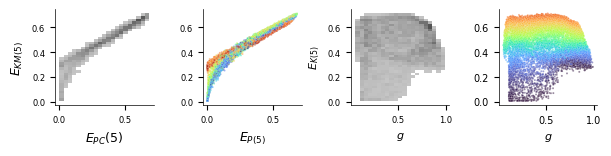

In [9]:
fig = plt.figure(figsize=(7,1.25))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,4,wspace=.5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])
#df.pca_error = np.log(df.pca_error)

sns.histplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,alpha = 1,legend= False, color='gray')
# sns.regplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})
#sns.regplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})


sns.scatterplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax1,alpha = .5,s=2, hue = 'gain_mean',legend=False,palette = 'turbo')

# sns.regplot(data = df,x = 'linear_error_train',y='kmeans_error',ax=ax1,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})

sns.histplot(data = df,x = 'gain_mean',y='kmeans_error',ax=ax2,alpha = 1,legend=False,color='gray')
#sns.scatterplot(data = df[df.pca_error<.1],x = 'linear_error_train',y='kmeans_error',ax=ax2,alpha = 1,s=2)
# sns.regplot(data = df[df.pca_error<.05],x = 'linear_error_train',y='kmeans_error',ax=ax2,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})

#sns.histplot(data = df[df.pca_error>.075],x = 'linear_error_train',y='kmeans_error',ax=ax3,alpha = .75,color='gray',legend=False)
#sns.histplot(data = df[df.pca_error<.075],x = 'linear_error_train',y='kmeans_error',ax=ax3,alpha = 1,legend=False)
sns.scatterplot(data = df,x = 'gain_mean',y='kmeans_error',ax=ax3,alpha = .5,s = 2,legend=False, hue = 'pca_error',palette = 'turbo',hue_norm = (0,.85))

# sns.regplot(data = df[df.pca_error<.1],x = 'linear_error_train',y='kmeans_error',ax=ax3,scatter_kws={'s': 2,'alpha' : 0},line_kws={'lw': .75,'color':'gray','linestyle':'--'})
#sns.scatterplot(data = df,x = 'pca_error',y='kmeans_error',ax=ax0,alpha = 1,legend=False)


# sns.histplot(data = df[(df.relative_test_loss>0.25) ],x = 'pca_error',y='kmeans_error',ax=ax1,alpha = 1,bins=35,cbar=True)
# sns.histplot(data = df[(df.relative_test_loss>0.5)   ],x = 'pca_error',y='kmeans_error',ax=ax2,alpha = 1,bins=35,cbar=True)
# sns.histplot(data = df[df.relative_test_loss>0.75],x = 'pca_error',y='kmeans_error',ax=ax3,alpha =1 ,bins=35,cbar=True)

# sns.histplot(data = df2,x = 'pca_error',y='kmeans_error',ax=ax0,alpha = 1,bins=35)
# sns.histplot(data = df2[df2.linear_error>0.3],x = 'pca_error',y='kmeans_error',ax=ax1,alpha = 1,bins=35)
# sns.histplot(data = df2[df2.linear_error>0.6],x = 'pca_error',y='kmeans_error',ax=ax2,alpha = 1,bins=35)
# sns.histplot(data = df2[df2.linear_error>0.9],x = 'pca_error',y='kmeans_error',ax=ax3,alpha = 1,bins=35)
#sns.histplot(data = df[(df.linear_error>.8)],x = 'pca_error',y='kmeans_error',alpha = .5,ax=ax2)

for ax in [ax0,ax1,ax2]:
    lims = [
            np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
            np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
        ]
    cbar = ax.figure.axes[-1]
    cbar.tick_params(labelsize=6)
    # now plot both limits against eachother
    # ax.plot(lims, lims, 'k-', alpha=0.15, zorder=0,lw=.5)
    # ax.set_aspect('equal')
    # ax.set_xlim(0,0.75)
    # ax.set_ylim(0,.75)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    #ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
    ax.xaxis.set_tick_params(labelsize=6, bottom=True)
    ax.yaxis.set_tick_params(labelsize=6, left=True)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')

ax0.set_xlabel(r"$E_{PC}(5)$", fontsize=9)
ax0.set_ylabel(r"$E_{KM(5)}$", fontsize=9)

ax1.set_xlabel(r"$E_{P(5)}$", fontsize=9)
ax1.set_ylabel("", fontsize=9)

ax2.set_xlabel(r"$g$", fontsize=8)
ax2.set_ylabel(r"$E_{K(5)}$", fontsize=8)

ax3.set_xlabel(r"$g$", fontsize=8)
ax3.set_ylabel("", fontsize=8)

ax3.spines['right'].set_visible(False)
ax3.spines['top'].set_visible(False)
ax3.spines['bottom'].set_visible(True)
ax3.spines['left'].set_visible(True)

#ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
ax3.xaxis.set_tick_params(labelsize=7, bottom=True)
ax3.yaxis.set_tick_params(labelsize=7, left=True)
ax3.spines['left'].set_color('black')
ax3.spines['bottom'].set_color('black')

plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

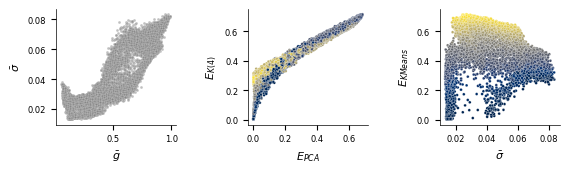

In [155]:
fig = plt.figure(figsize=(6.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .6)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
#df = df[df.gain_std<.015]
sns.scatterplot(data = df, x = 'gain_mean',y = 'snr_mean',s = 4,ax=ax0,alpha = .5,legend = False,color='gray')
#sns.regplot(data = df, x = 'gain_mean',y = 'snr',color='gray',ax=ax0,scatter_kws=dict(s=2),line_kws=dict(lw = 1),lowess = True)
sns.scatterplot(data = df, x = 'pca_error',y = 'kmeans_error',s = 4,hue='snr_mean',ax=ax1,legend = False,palette = 'cividis')
sns.scatterplot(data = df, x = 'snr_mean',y = 'kmeans_error',s = 4,hue='pca_error',ax=ax2,legend = False,palette = 'cividis')

for ax in [ax0,ax1,ax2]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    #ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
    ax.xaxis.set_tick_params(labelsize=6, bottom=True)
    ax.yaxis.set_tick_params(labelsize=6, left=True)
    ax.spines['left'].set_color('black')
    ax.spines['bottom'].set_color('black')

ax0.set_xlabel(r"$\bar{g}$",fontsize = 8)
ax0.set_ylabel(r"$\bar{\sigma}$",fontsize = 8)
ax1.set_xlabel(r"$E_{PCA}$",fontsize = 8)
ax1.set_ylabel(r"$E_{K(4)}$",fontsize = 8)
ax2.set_xlabel(r"$\bar{\sigma}$",fontsize = 8)
ax2.set_ylabel(r"$E_{KMeans}$",fontsize = 8)
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

<Axes: >

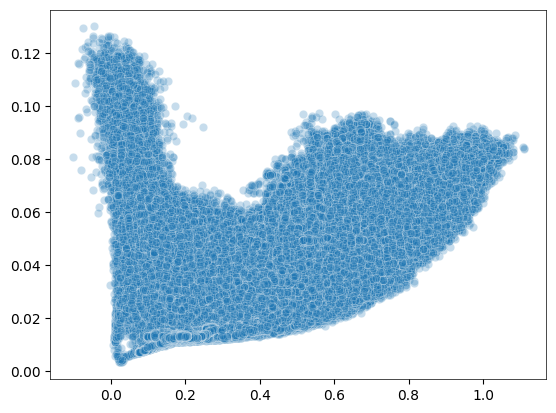

In [150]:
s = np.concatenate(df.snr.values)
g = np.concatenate(df.gain.values)
plt.figure()
sns.scatterplot(x = g,y = s,alpha = .25)

In [137]:
len(s)

914170

<Axes: xlabel='gain_mean', ylabel='Count'>

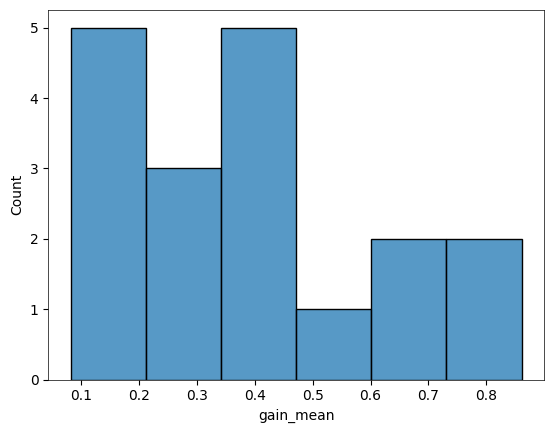

In [88]:
plt.figure()
sns.histplot(data = df, x= 'gain_mean')

In [109]:
df[df.pca_target_2<.05].gain_mean.min()

np.float64(0.07581333070993423)

In [29]:
df.non_linearity_1.min()

AttributeError: 'DataFrame' object has no attribute 'non_linearity_1'

In [30]:
sns.color_palette("coolwarm", 9)

[(0.34832334141176474, 0.4657111465098039, 0.8883461629411764),
 (0.48385432959999997, 0.6220498496, 0.9748082026),
 (0.6193179451882354, 0.7441207347647059, 0.9989309188196078),
 (0.753610618, 0.830232851, 0.960871157),
 (0.8674276350862745, 0.864376599772549, 0.8626024620196079),
 (0.9473454036, 0.7946955048, 0.7169905058),
 (0.9684997476666667, 0.673977379772549, 0.5566492560470588),
 (0.9318312966, 0.5190855232, 0.4064796086),
 (0.8393649370784314, 0.32185622094117644, 0.26492398098039216)]

In [31]:
plt.figure()
sns.histplot(data = df, x = 'linear_error_mean')

ValueError: Could not interpret value `linear_error_mean` for `x`. An entry with this name does not appear in `data`.

<Figure size 640x480 with 0 Axes>

In [32]:
df[(df.pca_error<.1) & (df.linear_error_mean>.2)].sort_values('kmeans_error',ascending = False)

AttributeError: 'DataFrame' object has no attribute 'linear_error_mean'

<Axes: xlabel='pca_1', ylabel='Count'>

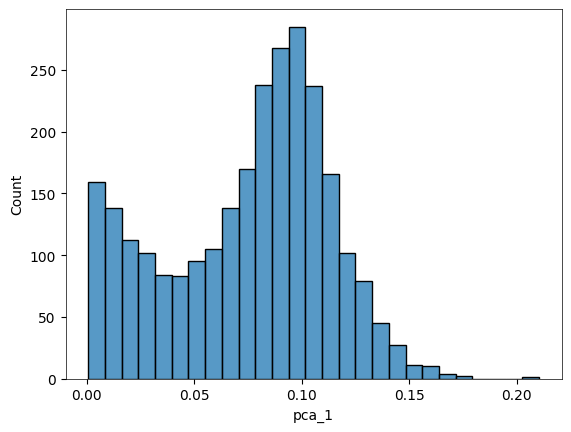

In [33]:
plt.figure()
sns.histplot(data =df, x = 'pca_1')

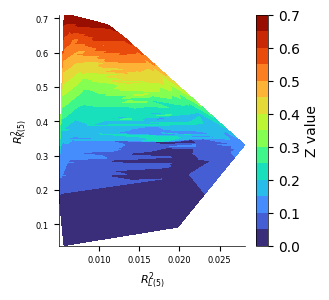

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a sample DataFrame with scattered data (replace with your data)
fig = plt.figure(figsize=(3,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])


# 2. Extract columns as 1D arrays
y = df['kmeans_error']
x = df['snr']
z = df['pca_error']

# 3. Plot the contour using tricontourf
plt.tricontourf(x, y, z, levels=15, cmap='turbo')
plt.colorbar(label='Z value')
# plt.xlabel('X column')
# plt.ylabel('Y column')
# plt.title('Contour Plot from Pandas DataFrame (Irregular Data)')
# plt.show()

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(True)
ax.spines['left'].set_visible(True)
#ax.set_title(r'$\sum_{i\geq 2}\lambda_eeeedrefswdei = $'+str(np.round(variance,4)),fontsize=8)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.spines['left'].set_color('black')
ax.spines['bottom'].set_color('black')
ax.set_xlabel(r"$R^2_{L(5)}$", fontsize=8)
ax.set_ylabel(r"$R^2_{K(5)}$", fontsize=8)

plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [246]:
import numpy as np

import plotly.graph_objects as go
from plotly.subplots import make_subplots




#Define subplots of 1 row and two columns. In the subplot (1,1) draw the surface of equation z=f(x,y) and the cutting plane
#perpendicular on the plane z=0, while in (1,2) the resulted curve.

fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])
#


#sub_df = new_df[(new_df.t==130)]
fig.add_trace(go.Scatter3d(x=df.kmeans_error.values,
                          y=df.gain_mean.values,
                          z=df.pca_error.values,
                              mode='markers',

                        marker=dict(
                            color=df.gain_mean.values,
                            colorscale = "turbo",
                            size=2,
                            opacity=1,


                        )), row=1, col=1)
#


fig.update_layout( scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False),

             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )

In [96]:

u, z, mask, conditions = generate_trials(n_trials=5)

import numpy as np
import statsmodels.api as sm
import pandas as pd
#
net = Net(n=100, input_size=u.shape[2],output_size=u.shape[2],
          dale=False,
          sigma_in=0.,
          base_in=0,
          lambda_std=0.4,
          beta=10)


# Fit with penalty
dim = 4
lds = net.fit(u,
        z,
        mask,
        lr=.001,
        epochs=3000,
        conditions=conditions,
        verbose=True,
        dim=dim,
        weight_decay=0.001,
        kmeans_target=0,
        pca_target_1=0,
        pca_target_2=0,
        linear_target=0,
        lambda_kmeans=.5,
        lambda_pca_1=.5,
        lambda_pca_2=1,
        lambda_linear=.5,
        lambda_linear_std=0.1,
                            )

Epoch: 50/3000............. pca: 0.0244 pca_1: 0.0371 kmeans: 0.1617 lds: 0.1207
Epoch: 100/3000............. pca: 0.0175 pca_1: 0.0405 kmeans: 0.1252 lds: 0.1138
Epoch: 150/3000............. pca: 0.0134 pca_1: 0.0434 kmeans: 0.1063 lds: 0.0689
Epoch: 200/3000............. pca: 0.0112 pca_1: 0.0555 kmeans: 0.0948 lds: 0.0749
Epoch: 250/3000............. pca: 0.0095 pca_1: 0.0684 kmeans: 0.0858 lds: 0.0886
Epoch: 300/3000............. pca: 0.0084 pca_1: 0.0604 kmeans: 0.0794 lds: 0.0861
Epoch: 350/3000............. pca: 0.0068 pca_1: 0.0643 kmeans: 0.0706 lds: 0.0813
Epoch: 400/3000............. pca: 0.0062 pca_1: 0.0647 kmeans: 0.0659 lds: 0.0767
Epoch: 450/3000............. pca: 0.0052 pca_1: 0.0648 kmeans: 0.0599 lds: 0.0816
Epoch: 500/3000............. pca: 0.0043 pca_1: 0.0658 kmeans: 0.0534 lds: 0.0791
Epoch: 550/3000............. pca: 0.0035 pca_1: 0.0871 kmeans: 0.0486 lds: 0.0699
Epoch: 600/3000............. pca: 0.0027 pca_1: 0.1359 kmeans: 0.0425 lds: 0.0717
Epoch: 650/3000..

In [40]:

net = torch.load('FigureModels/LinearBoundaries/model_1.pth',weights_only=False)

In [97]:
from sklearn.cluster import KMeans

def compute_kmeans_error(dim, responses):
    kmeans = KMeans(n_clusters=dim, init='random', n_init=10).fit(responses)

    responses = responses / np.linalg.norm(responses, axis=1, keepdims=True)
    predicted_responses = np.zeros_like(responses)

    for neuron in range(responses.shape[0]):
        predicted_responses[neuron, :] = kmeans.cluster_centers_[kmeans.labels_[neuron], :]
    predicted_responses = predicted_responses / np.linalg.norm(predicted_responses, axis=1, keepdims=True)

    angles = []
    for neuron in range(responses.shape[0]):
        angles.append(
            np.arccos(np.clip(np.dot(predicted_responses[neuron, :], responses[neuron, :]), -1, 1)) / np.pi * 2)

    return np.mean(angles)

dim = 4
u, z, mask, conditions = generate_trials(n_trials=1,n_t = 75,n_conditions =200)
x = net(u)
x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()
kmeans_error = compute_kmeans_error(dim, x.reshape(-1,x.shape[2]).T)
kmeans_error

np.float32(0.0073661143)

In [98]:
from Experiment_10.net import LDS
u, z, mask, conditions = generate_trials(n_trials=5,n_t = 75,n_conditions =100)
x = net(u)
#x = iterative_outlier_detection(x)

x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach()

lds = LDS(n=dim, input_size = 2,output_size=x.shape[2])
lds.fit(u, x, epochs=1000,lr = .01)
y = lds.output_layer(lds(u))

pca = PCA(n_components=dim).fit(x.reshape(-1, x.shape[2]).detach().numpy())
pcs = torch.tensor(pca.components_[:dim, :]).float()
linear_prediction_proj = y#@ pcs.t() @ pcs
x_proj = x #@ pcs.t() @ pcs

# Compute error of LDS prediction
linear_error_mean,linear_error_std = net.linear_error(linear_prediction_proj, x_proj)

linear_error_mean, linear_error_std

(tensor(0.0106, grad_fn=<MeanBackward0>),
 tensor(0.0055, grad_fn=<StdBackward0>))

In [44]:
lds

LDS(
  (recurrent_layer): Sequential(
    (0): Linear(in_features=4, out_features=100, bias=True)
    (1): Linear(in_features=100, out_features=4, bias=True)
  )
  (input_layer): Linear(in_features=2, out_features=4, bias=True)
  (output_layer): Linear(in_features=4, out_features=100, bias=True)
  (x0_layer): Linear(in_features=2, out_features=4, bias=True)
)

<Axes: xlabel='None', ylabel='Count'>

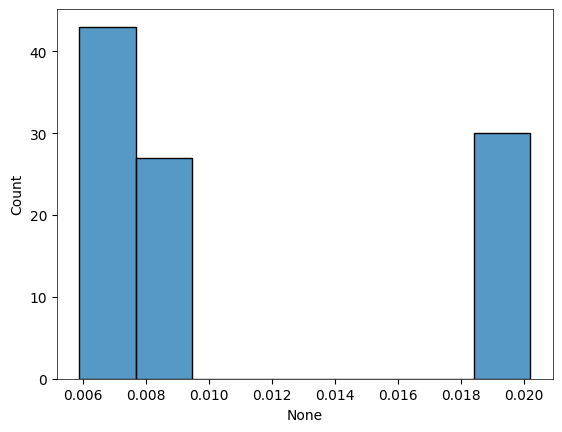

In [99]:

s = torch.sum((x - y) ** 2, dim=[0, 1]) / torch.sum((x) ** 2, dim=[0, 1])
errors_mean = torch.mean(s)


errors_std = torch.std(s)
plt.figure()
sns.histplot(x = s.detach())

In [221]:
u, z, mask, conditions = generate_trials(n_trials=1,n_t = 1000,n_conditions =500)
net.alpha = .02

x = net(u)
x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach()

y = lds.output_layer(lds(u)).detach()

In [222]:
400*.4

160.0

In [223]:


pca = PCA().fit(x.reshape(-1,x.shape[2]))



#
x = x[:,800:900,:]
u = u[:,800:900,:]
y = y[:,800:900,:]

# lds = LDS(n=dim, input_size = 2,output_size=x.shape[2],alpha = .025)
# lds.fit(u, x, epochs=1000,lr = .01)
# y = lds.output_layer(lds(u)).detach()
rows = []
points = torch.tensor(x[:,:,:])
#net.recurrent_layer.weight.data = net.recurrent_layer.weight.data + .005*(2*torch.randn_like(net.recurrent_layer.weight.data)-1)
hpoints = net.recurrent_layer(points)+net.input_layer(u[:,:,:])
flow_field = -points + net.activation(hpoints)
curvature = (flow_field @ net.recurrent_layer.weight.data.t())**2 * (torch.clamp(torch.exp(10*hpoints),max = 1e6)/(1+torch.clamp(torch.exp(10*hpoints),max = 1e6))**2)
for trial in range(x.shape[0]):
    trajectory = x[trial,:,:]
    proj_trajectory = pca.transform(trajectory)
    predicted_trajectory = y[trial,:,:]
    proj_predicted_trajectory = pca.transform(predicted_trajectory)

    for t in range(x.shape[1]):

        boundary = torch.mean((torch.clamp(torch.exp(100*hpoints[trial,t,:]),max = 1e6)/(1+torch.clamp(torch.exp(100*hpoints[trial,t,:]),max = 1e6))**2))

        curvature_norm = torch.linalg.norm(curvature)
        rows.append({'t': t,
                     'theta': conditions[trial]['theta'],
                     'x': proj_trajectory[t,0],
                     'y': proj_trajectory[t,1],
                     'z': proj_trajectory[t,2],
                     'x_pred': proj_predicted_trajectory[t,0],
                     'y_pred': proj_predicted_trajectory[t,1],
                     'z_pred': proj_predicted_trajectory[t,1],
                     'c': torch.linalg.norm(curvature[trial,t,:]).item(),
                     'b': boundary.item(),})

new_df = pd.DataFrame(rows)

x.shape

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_42458/1843050316.py:14: UserWarning:

To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).



torch.Size([500, 100, 100])

In [224]:
torch.save(net,'FigureModels/LinearBoundaries/model_1.pth')

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_42458/4031761120.py:11: UserWarning:

The palette list has more values (2000) than needed (500), which may not be intended.

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_42458/4031761120.py:14: UserWarning:

The palette list has more values (2000) than needed (500), which may not be intended.

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_42458/4031761120.py:17: UserWarning:

The palette list has more values (2000) than needed (500), which may not be intended.

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_42458/4031761120.py:20: UserWarning:

The palette list has more values (2000) than needed (500), which may not be intended.



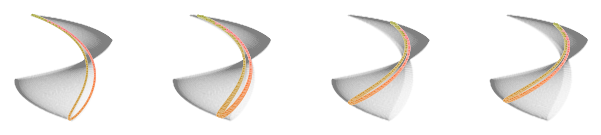

In [225]:

fig = plt.figure(figsize=(7.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,4,wspace=.5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])


sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax0,legend=False,color='gray',alpha = .025,lw=0)
sns.scatterplot(data = new_df[(new_df.t==1)], x = 'x', y = 'y',s=2, hue = 'theta',ax=ax0,legend=False,palette = sns.husl_palette(2000))

sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax1,legend=False,color='gray',alpha = .025,lw=0)
sns.scatterplot(data = new_df[(new_df.t>5) & (new_df.t<10)], x = 'x', y = 'y',s=2, hue = 'theta',ax=ax1,legend=False,palette = sns.husl_palette(2000))

sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax2,legend=False,color='gray',alpha = .025,lw=0)
sns.scatterplot(data = new_df[(new_df.t>35) & (new_df.t<40) ], x = 'x', y = 'y',s=2, hue = 'theta',ax=ax2,legend=False,palette = sns.husl_palette(2000))

sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax3,legend=False,color='gray',alpha = .025,lw=0)
sns.scatterplot(data = new_df[(new_df.t>40) & (new_df.t<45)], x = 'x', y = 'y',s=2, hue = 'theta',ax=ax3,legend=False,palette = sns.husl_palette(2000))


for ax in [ax0,ax1,ax2,ax3]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)

plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


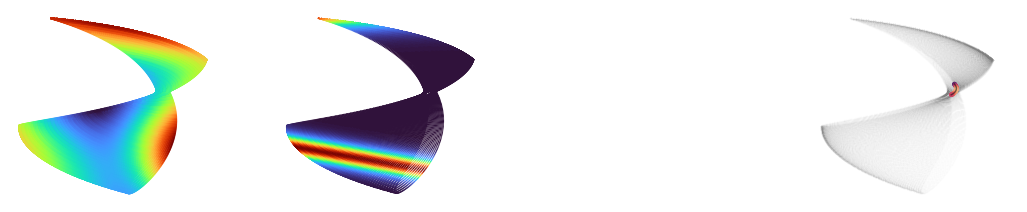

In [226]:
# Curvature of trajectories and linear boundaries

fig = plt.figure(figsize=(13,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,4,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])

# Curvature
sns.scatterplot(data = new_df, x = 'x', y = 'y',s=2.5,ax=ax0,legend=False,alpha = 1,lw=0,hue = 'c',palette ='turbo')

# Distance to boundary
sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax1,legend=False,alpha = 1,lw=0,hue = 'b',palette ='turbo')

# Linear error
#sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax2,legend=False,alpha = .05,lw=0,hue = 'd',palette ='turbo')

# Linear error (single trajectory)

sns.scatterplot(data = new_df, x = 'x', y = 'y',s=1,ax=ax3,legend=False,color='gray',alpha = .02,lw=0)

# theta = new_df.theta.unique()[104]
# sub_df = new_df[(new_df.theta==theta) & (new_df.t<30)]
# sns.scatterplot(data = sub_df, x = 'x', y = 'y',s=10,ax=ax3,legend=False,alpha = 1,lw=0,hue = 'c',palette = "flare_r")
# ax3.plot( sub_df.x.values, sub_df.y.values,color ='k',alpha = .5,lw=1)
# ax3.plot( sub_df.x_pred.values, sub_df.y_pred.values,color ='k',linestyle='--',alpha = .5,lw=1)

theta = new_df.theta.unique()[110]
sub_df = new_df[(new_df.theta==theta) & (new_df.t>=0)]
sns.scatterplot(data = sub_df, x = 'x', y = 'y',s=10,ax=ax3,legend=False,alpha = 1,lw=0,hue = 'c',palette = "flare_r")
ax3.plot( sub_df.x.values, sub_df.y.values,color ='k',alpha = .5,lw=1)
ax3.plot( sub_df.x_pred.values, sub_df.y_pred.values,color ='k',linestyle='--',alpha = .5,lw=1)


for ax in [ax0,ax1,ax2,ax3]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


In [227]:
import numpy as np

import plotly.graph_objects as go
from plotly.subplots import make_subplots




xx = np.linspace(-15, 15, 200)
yy = np.linspace(-15, 15, 300)
x,y = np.meshgrid(xx, yy)

zz = np.linspace(z.min(), z.max(), 100)
x = net(u).detach().numpy()
std = np.std(x,axis=(0,1))


#Define subplots of 1 row and two columns. In the subplot (1,1) draw the surface of equation z=f(x,y) and the cutting plane
#perpendicular on the plane z=0, while in (1,2) the resulted curve.

fig = make_subplots(
     rows=1, cols=1,
     specs=[[{"type": "scene"}]])
#
# fig.add_trace(go.Surface(x=X, y=Y, z=Z,
#                          colorscale= [[0, "rgb(254, 254, 254)"],
#                                       [1, "rgb(254, 254, 254)"]],
#                          showscale=False,
#                          opacity =1), row=1, col=1)
sub_df = new_df

# fig.add_trace(go.Scatter3d(x=sub_df.x.values,
#                           y=sub_df.y.values,
#                           z=sub_df.z.values,
#                               mode='markers',
#                         marker=dict(
#                             color=sns.color_palette("turbo",100)[10],
#                             size=.3,
#                             opacity=1
#                         )), row=1, col=1)

#sub_df = new_df[(new_df.t==130)]
fig.add_trace(go.Scatter3d(x=sub_df.x.values,
                          y=sub_df.y.values,
                          z=sub_df.z.values,
                              mode='markers',
                        marker=dict(
                            color=sub_df.b.values,
                            colorscale = "turbo",
                            size=.5,
                            opacity=1
                        )), row=1, col=1)

# sub_df = new_df[(new_df.theta==0)]
# fig.add_trace(go.Scatter3d(x=sub_df.x.values,
#                           y=sub_df.y.values,
#                           z=sub_df.z.values,
#                               mode='markers',
#                         marker=dict(
#                             color='purple',
#                             size=2,
#                             opacity=1
#                         )), row=1, col=1)
#


# fig.add_trace(go.Scatter3d(x=sub_df.x.values,
#                           y=sub_df.y.values,
#                           z=sub_df.z.values,
#                               mode='markers',
#                         marker=dict(
#                             color='white',
#                             size=1,
#                             opacity=1
#                         )), row=1, col=1)
#
# fig.add_trace(go.Scatter3d(x=sub_df.x_pred.values,
#                           y=sub_df.y_pred.values,
#                           z=sub_df.z_pred.values,
#                               mode='markers',
#                         marker=dict(
#                             color='gray',
#                             size=1,
#                             opacity=1
#                         )), row=1, col=1)


# fig.add_trace(go.Surface(x=x,
#                           y=y,
#                           z=z,
#                           colorscale="Viridis",
#                           showscale=False), row=1, col=1)
#)
#fig.add_trace(go.Scatter(x= xx, y = g(xx), mode="lines"), row=1, col=2)

fig.update_layout(scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False)
             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )

In [210]:
sns.color_palette("turbo",100)[3]

(0.23236, 0.18603, 0.50004)

In [149]:
200 * .4

80.0

<Axes: >

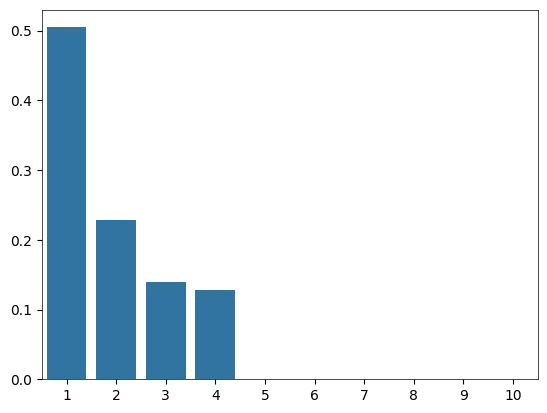

In [150]:
# Dimensionality
x = net(u)
x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach().numpy()

pca = PCA().fit(x.reshape(-1,x.shape[2]))
plt.figure()
sns.barplot(x = np.arange(1,11),y = pca.explained_variance_ratio_[:10])

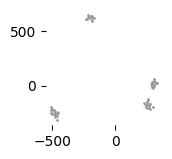

In [198]:
x = net(u).detach()
x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x  + 10*(2*torch.rand_like(x)-1)
x = x.numpy()

x_proj  = PCA().fit_transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1,wspace = .3)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax,s=4,color='gray')
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
# ax.axes.get_xaxis().set_visible(False)
# ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_1_c.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [ ]:
u, z, mask, conditions = generate_trials(n_trials=5,n_t = 20,n_conditions =50)
net.alpha = .025
x = net(u)

x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x.detach()

#
x = x[:,200:100,:]
u = u[:,200:100,:]
#y = y[:,200:400,:]


In [ ]:
net.alpha = .2

In [ ]:
torch.save(net,'FigureModels/BoundariesandCurvature/model_1.pth')

In [ ]:
lds = LDS(n=dim, input_size = 2,output_size=x.shape[2])
lds.fit(u, x, epochs=4000,lr = .01)
y = lds.output_layer(lds(u)).detach()

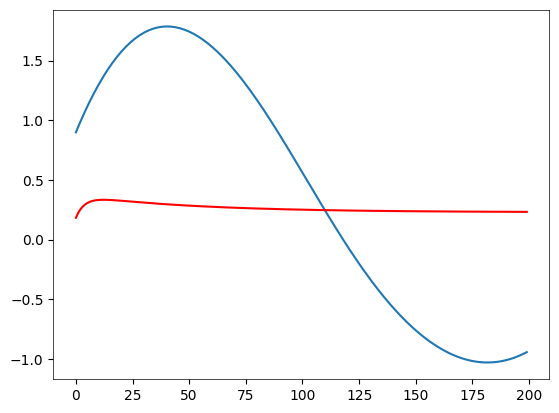

In [199]:
plt.figure()
plt.plot(x[4,:,2])
plt.plot(y[4,:,2],color='red')

In [270]:
import plotly.graph_objects as go
import numpy as np

# 1. Generate Sphere Data
phi = np.linspace(0, 2*np.pi, 50)
theta = np.linspace(0, np.pi, 50)
r = 5 # Sphere Radius
x_s = r * np.outer(np.cos(phi), np.sin(theta))
y_s = r * np.outer(np.sin(phi), np.sin(theta))
z_s = r * np.outer(np.ones(50), np.cos(theta))

# 2. Generate Plane Data (e.g., z = 2)
x_p, y_p = np.meshgrid(np.linspace(-4, 4, 10), np.linspace(-4, 4, 10))
z_p = np.ones(x_p.shape) * 5

# 3. Plot
fig = go.Figure(data=[
    go.Surface(x=x_s, y=y_s, z=z_s, opacity=1, colorscale='Viridis', showscale=False),
    go.Surface(x=x_p, y=y_p, z=z_p, opacity=.8, colorscale='Gray', showscale=False)
])

fig.update_layout(title='Sphere Intersecting Plane',
                  scene=dict(xaxis_title='X', yaxis_title='Y', zaxis_title='Z'))

fig.update_layout(scene = dict(xaxis = dict(showgrid = False,showticklabels = False),
                                   yaxis = dict(showgrid = False,showticklabels = False),
                                   zaxis = dict(showgrid = False,showticklabels = False)
             ))
fig.update_scenes(xaxis_visible=False, yaxis_visible=False,zaxis_visible=False )
fig.show()
